In [1]:
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt

In [2]:
str_url = "https://docs.google.com/spreadsheets/d/e/2PACX-1vRfNroFE_THBtcNXvqGmIjAznHFN7d7J_oaBaUWbuGwCnpifPfAcDWDZJcgRsJ13efcmQu1LcNeXCmq/pub?output=xlsx"

In [3]:
df = pd.read_excel(str_url, sheet_name="Market_Data", index_col="DATE").sort_index()

In [4]:
df.columns.to_list()

['KOSPI',
 'KOSDAQ',
 'DJIA',
 'SPX',
 'CCMP',
 'SPTSX',
 'EUROSTOXX',
 'FTSE',
 'DAX',
 'CAC',
 'NIKKEI',
 'HIS',
 'SHS',
 'WTI',
 'BRENT',
 'XAU',
 'BTC',
 'VIX',
 'DXY',
 'KRWNDF_1M',
 'USDKRW',
 'JPYKRW',
 'EURKRW',
 'CHFKRW',
 'GBPKRW',
 'CADKRW',
 'AUDKRW',
 'NZDKRW',
 'CNYKRW',
 'HKDKRW',
 'IDRKRW',
 'SGDKRW',
 'THBKRW',
 'USDJPY',
 'EURUSD',
 'GBPUSD',
 'USDCHF',
 'USDCAD',
 'AUDUSD',
 'NZDUSD',
 'USDCNH',
 'USDCNY',
 'USDHKD',
 'USDIDR',
 'USDSGD',
 'FED_U',
 'FED_L',
 'BOC',
 'BOJ',
 'BOK',
 'RBA',
 'ECB',
 'BOE',
 'DDEP',
 'CDEP',
 'TDEP_1W',
 'TDEP_1M',
 'TDEP_3M',
 'TDEP_6M',
 'UST_1M',
 'UST_3M',
 'UST_6M',
 'UST_1Y',
 'UST_2Y',
 'UST_3Y',
 'UST_5Y',
 'UST_7Y',
 'UST_10Y',
 'UST_20Y',
 'UST_30Y',
 'KRW_CALL_ON',
 'KTB_3M',
 'KTB_6M',
 'KTB_1Y',
 'KTB_2Y',
 'KTB_3Y',
 'KTB_5Y',
 'KTB_10Y',
 'KTB_20Y',
 'KTB_30Y',
 'MSB_3M',
 'MSB_1Y',
 'MSB_2Y',
 'CD_3M',
 'CP_3M',
 'KORIBOR_1M',
 'KORIBOR_3M',
 'KORIBOR_6M',
 'KORIBOR_12M',
 'IMP_FF_ON',
 'SOFR_ON',
 'SOFR_1M',
 'SOFR_3M'

In [10]:
def data_extract(tickers):
    ''' ticker should in list format '''
    data = df[tickers]
    data = data.dropna()
    return data

In [37]:
cols = ["BOK", "KOFROIS_ON", "KOFROIS_1Y", "KOFROIS_2Y"]

kofr = data_extract(cols)

kofr["1y1y"] = (((1 + kofr["KOFROIS_2Y"]/100)**2 / (1 + kofr["KOFROIS_1Y"]/100)) - 1) * 100
kofr["Imp_Basis"] = (kofr["1y1y"] - kofr["KOFROIS_ON"]) * 100

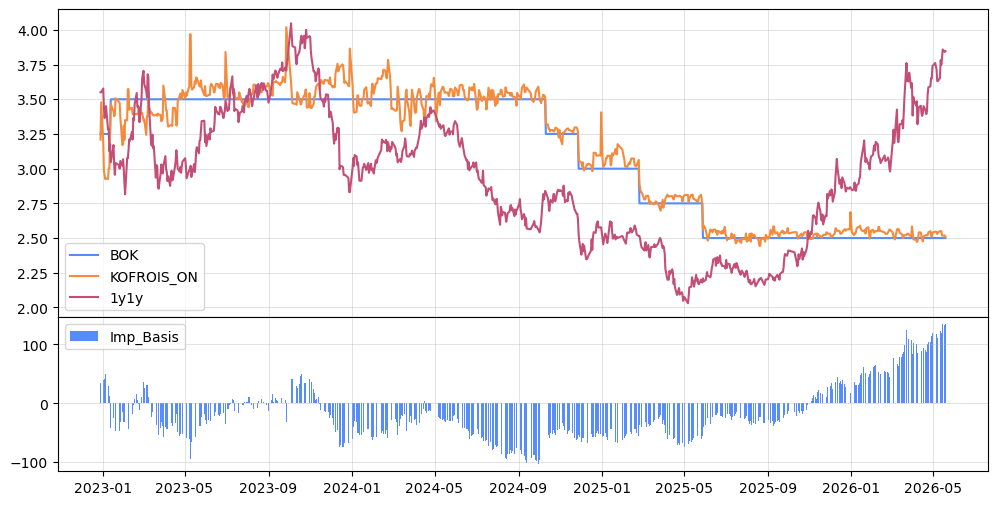

In [44]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, height_ratios=(2, 1))
fig.subplots_adjust(hspace=0)

ax1.plot(kofr.index, kofr[["BOK", "KOFROIS_ON", "1y1y"]], label=["BOK", "KOFROIS_ON", "1y1y"])
ax2.bar(kofr.index, kofr["Imp_Basis"], label="Imp_Basis")

for ax in [ax1, ax2]:
    ax.grid()
    ax.legend()

plt.show()